# H1: Adaptive TCT vs Standard IDP — Main Experiments

**Hypothesis H1:** Adaptive TCT allows the system to answer more queries before a given fraction of users exhaust their privacy budget, compared to Standard IDP.

This notebook presents four figures building toward that claim:

| Section | Content | Key message |
|---|---|---|
| 1 | Theoretical cost curves | Adaptive TCT vs Standard TCT |
| 2 | Full participation, no interleaving | Clearest TCT advantage; Standard DP exhausts 5× sooner |
| 3 | Full participation, with interleaving | TCT advantage persists even when 50% of rounds are non-TCT |
| 4 | Partial participation (50%), with interleaving | Adding individual privacy further widens the gap |

**Charging semantics recap:**
- *Standard DP*: charges ε to every sampled user on every round, regardless of contribution or threshold outcome.
- *Adaptive TCT*: charges K₁·ε at registration (once), then incremental charges only on rounds where (i) the threshold is crossed and (ii) the user personally contributed. Non-TCT rounds charge ε directly.

In [27]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_dp import StandardDPAccountant
from simulation.accountants.standard_tct import StandardTCTAccountant
from simulation.calibration import q_from_epsilon
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.query import compute_round_conversions, laplace_threshold_query

plt.rcParams.update({
    'figure.dpi': 150,
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'legend.fontsize': 8.5,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'lines.linewidth': 2.0,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

TCT_COLOR  = '#2166ac'   # Adaptive TCT — blue
IDP_COLOR  = '#d6604d'   # Standard IDP — red
STCT_COLOR = '#1a9641'   # Standard TCT — green

In [28]:
# ── Shared parameters ─────────────────────────────────────────────────────────
EPSILON          = 0.01     # per-query ε; q = 1/(e^ε+1) ≈ 0.4975
DELTA            = 1e-2     # TCT failure probability
N_USERS          = 5000
N_ROUNDS         = 500
EPS_BUDGET       = 1.0      # per-user ε budget
TARGET_HIT_RATE  = 0.05     # desired fraction of TCT rounds that cross threshold
ALPHA_POP        = 0.5      # Beta(α, β) for conversion rates; E[rate] = α/(α+β) = 0.20
BETA_POP         = 2.0
P_PART           = 0.5      # partial-participation fraction (Sections 4, 5)
INTERLEAVE       = 0.5      # fraction of non-TCT rounds (Sections 3, 4, 5)
SEED             = 42
N_PILOT          = 3000

q = q_from_epsilon(EPSILON)
pop_cfg = PopulationConfig(
    n_users=N_USERS, alpha=ALPHA_POP, beta=BETA_POP,
    epsilon_budget=EPS_BUDGET, delta_budget=1.0,
)

print(f'ε={EPSILON}, q={q:.4f},  δ={DELTA}')
print(f'E[conversion rate] = {ALPHA_POP/(ALPHA_POP+BETA_POP):.3f}')
print()

# Key cost landmarks
acc_ref = AdaptiveTCTAccountant(EPSILON, DELTA)
K1 = acc_ref.compositions(1)
print(f'K₁ = {K1:.1f},   K₁·ε = {K1*EPSILON:.3f}  (registration cost)')
print(f'Standard IDP exhaustion:')
print(f'  Full participation:    {EPS_BUDGET/EPSILON:.0f} rounds')
print(f'  Partial (p={P_PART}):  {EPS_BUDGET/(P_PART*EPSILON):.0f} rounds')
print(f'  Full + interleave:     same ({EPS_BUDGET/EPSILON:.0f} rounds — interleave has no effect on IDP)')

ε=0.01, q=0.4975,  δ=0.01
E[conversion rate] = 0.200

K₁ = 24.4,   K₁·ε = 0.244  (registration cost)
Standard IDP exhaustion:
  Full participation:    100 rounds
  Partial (p=0.5):  200 rounds
  Full + interleave:     same (100 rounds — interleave has no effect on IDP)


In [29]:
# ── Calibration ───────────────────────────────────────────────────────────────
def calibrate_threshold(pop_cfg, p_participate=1.0, seed=SEED):
    """Find T achieving TARGET_HIT_RATE, with the given participation model."""
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    noisy_counts = np.empty(N_PILOT)
    for i in range(N_PILOT):
        active = pop.active_users
        parts = (list(active) if p_participate >= 1.0
                 else [u for u in active if rng.random() < p_participate])
        if not parts:
            noisy_counts[i] = rng.laplace(0.0, 1.0 / EPSILON)
            continue
        cnt, _ = compute_round_conversions(parts, rng)
        noisy_counts[i] = cnt + rng.laplace(0.0, 1.0 / EPSILON)
    T = float(np.quantile(noisy_counts, 1.0 - TARGET_HIT_RATE))
    return T, float(np.mean(noisy_counts >= T))


# ── Main simulation loop ──────────────────────────────────────────────────────
def run_simulation(accountant_factory, pop_cfg, threshold,
                   p_participate=1.0, interleave_ratio=0.0, seed=SEED):
    """
    Run one simulation trial.

    Each round:
      - Sample participants (all active if p_participate=1, else Bernoulli(p)).
      - With probability (1 - interleave_ratio): TCT round — run Laplace query,
        charge via accountant.
      - Otherwise: non-TCT round — charge ε directly to all participants
        (standard DP composition, bypasses TCT logic).

    Standard IDP is unaffected by interleave_ratio: it charges ε per
    participating round regardless (via accountant or direct charge).
    Adaptive TCT benefits because TCT rounds are mostly free; only non-TCT
    rounds cost the full ε.
    """
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    acc = accountant_factory()
    active_frac, avg_budget, hit_rounds = [], [], []

    for r in range(N_ROUNDS):
        active = pop.active_users
        if not active:
            break
        parts = (list(active) if p_participate >= 1.0
                 else [u for u in active if rng.random() < p_participate])
        if parts:
            is_tct = (interleave_ratio == 0.0 or rng.random() >= interleave_ratio)
            if is_tct:
                cnt, contributions = compute_round_conversions(parts, rng)
                is_top, _ = laplace_threshold_query(cnt, threshold, EPSILON, rng)
                if is_top:
                    hit_rounds.append(r)
                for i, user in enumerate(parts):
                    e, d = acc.charge(user=user, is_top=is_top,
                                      contributed=contributions[i], round_num=r)
                    user.epsilon_spent += e
                    user.delta_spent   += d
            else:
                # Non-TCT round: ε to all participants, same for both accountants
                for user in parts:
                    user.epsilon_spent += EPSILON

        pop.drop_depleted()
        eps_dist = pop.epsilon_remaining_distribution()
        active_frac.append(pop.active_fraction)
        avg_budget.append(float(np.mean(eps_dist)) if eps_dist else 0.0)

    return active_frac, avg_budget, hit_rounds


# ── Single-panel plotting helper ──────────────────────────────────────────────
def half_life(active_frac, threshold=0.5):
    for r, f in enumerate(active_frac):
        if f <= threshold:
            return r
    return len(active_frac)


def pad(curve, n, fill=None):
    fill = (curve[-1] if curve else 0.0) if fill is None else fill
    return list(curve) + [fill] * (n - len(curve))


def plot_h1_panel(axes, tct_frac, tct_budget, idp_frac, idp_budget,
                  hl_tct, hl_idp, title_left, title_right, label_suffix=''):
    """Render one 2-panel (retention, degradation) figure onto provided axes."""
    n = max(len(tct_frac), len(idp_frac)) + 1
    rnds  = list(range(n))
    tct_a = pad(tct_frac,   n)
    idp_a = pad(idp_frac,   n)
    tct_b = pad(tct_budget, n)
    idp_b = pad(idp_budget, n)

    ax = axes[0]
    ax.plot(rnds, tct_a, color=TCT_COLOR, lw=2,
            label=f'Adaptive TCT{label_suffix}  (half-life = {hl_tct})')
    ax.plot(rnds, idp_a, color=IDP_COLOR, lw=2, linestyle='--',
            label=f'Standard DP  (half-life = {hl_idp})')
    ax.fill_between(rnds, idp_a, tct_a, alpha=0.10, color=TCT_COLOR,
                    label=f'+{hl_tct - hl_idp} rounds advantage')
    ax.axhline(0.5,    color='#888', lw=0.8, linestyle=':', zorder=0)
    ax.axvline(hl_tct, color=TCT_COLOR, lw=0.8, linestyle=':', alpha=0.6)
    ax.axvline(hl_idp, color=IDP_COLOR, lw=0.8, linestyle=':', alpha=0.6)
    ax.set_xlabel('Query round')
    ax.set_ylabel('Fraction of users active')
    ax.set_title(title_left)
    ax.set_xlim(0, n - 1)
    ax.set_ylim(-0.03, 1.05)
    ax.legend(loc='upper right')

    ax = axes[1]
    ax.plot(rnds, tct_b, color=TCT_COLOR, lw=2, label='Adaptive TCT')
    ax.plot(rnds, idp_b, color=IDP_COLOR, lw=2, linestyle='--', label='Standard DP')
    ax.fill_between(rnds, idp_b, tct_b,
                    where=[t >= i for t, i in zip(tct_b, idp_b)],
                    alpha=0.10, color=TCT_COLOR)
    ax.axhline(0, color='#888', lw=0.5, zorder=0)
    ax.set_xlabel('Query round')
    ax.set_ylabel('Mean remaining privacy budget (ε)')
    ax.set_title(title_right)
    ax.set_xlim(0, n - 1)
    ax.set_ylim(bottom=0)
    ax.legend(loc='upper right')


# ── Robustness helpers (shared by Sections 2, 3, 4) ──────────────────────────
ROBUST_SETTINGS = [
    {'label': 'A  (δ=1e-2, moderate)', 'delta': 1e-2, 'alpha': 0.5, 'beta': 2.0},
    {'label': 'B  (δ=1e-3, moderate)', 'delta': 1e-3, 'alpha': 0.5, 'beta': 2.0},
    {'label': 'C  (δ=1e-2, sparse)',   'delta': 1e-2, 'alpha': 0.3, 'beta': 3.0},
]


def run_robust_settings(settings, p_participate, interleave_ratio, seed=SEED):
    """Run TCT vs IDP for all settings; return list of result dicts."""
    results = []
    for s in settings:
        cfg = PopulationConfig(
            n_users=N_USERS, alpha=s['alpha'], beta=s['beta'],
            epsilon_budget=EPS_BUDGET, delta_budget=1.0,
        )
        thr, _ = calibrate_threshold(cfg, p_participate=p_participate)
        tct_f, tct_b, _ = run_simulation(
            lambda d=s['delta']: AdaptiveTCTAccountant(EPSILON, d, independent=True),
            cfg, thr, p_participate=p_participate,
            interleave_ratio=interleave_ratio, seed=seed)
        idp_f, idp_b, _ = run_simulation(
            lambda: StandardDPAccountant(EPSILON),
            cfg, thr, p_participate=p_participate,
            interleave_ratio=interleave_ratio, seed=seed)
        hl_t   = half_life(tct_f)
        hl_i   = half_life(idp_f)
        k1     = AdaptiveTCTAccountant(EPSILON, s['delta']).compositions(1)
        e_rate = s['alpha'] / (s['alpha'] + s['beta'])
        results.append(dict(s,
            tct_frac=tct_f, tct_budget=tct_b,
            idp_frac=idp_f, idp_budget=idp_b,
            hl_tct=hl_t, hl_idp=hl_i, advantage=hl_t - hl_i,
            k1=k1, e_rate=e_rate,
        ))
        print(f"{s['label']:30s}  K₁·ε={k1*EPSILON:.3f}  "
              f"TCT_hl={hl_t}  IDP_hl={hl_i}  adv=+{hl_t-hl_i}")
    return results


def plot_robust_settings(results, title_suffix, fig_path):
    """3×2 robustness grid — mirrors plot_h1_panel across 3 settings."""
    fig, axes = plt.subplots(3, 2, figsize=(9, 11))
    for row, res in enumerate(results):
        tag = (f"δ={res['delta']:.0e}, E[rate]={res['e_rate']:.3f}, "
               f"K₁·ε={res['k1']*EPSILON:.3f}")
        plot_h1_panel(
            axes[row],
            res['tct_frac'], res['tct_budget'],
            res['idp_frac'], res['idp_budget'],
            res['hl_tct'], res['hl_idp'],
            f"Setting {chr(65+row)}: Retention  ({tag})",
            f"Setting {chr(65+row)}: Degradation",
        )
        if row < 2:
            for ax in axes[row]:
                ax.set_xlabel('')
    fig.suptitle(f'Robustness — {title_suffix}', fontsize=11)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(fig_path, bbox_inches='tight', dpi=200)
    plt.show()


# ── Threshold calibration (done once per participation model) ─────────────────
print('Calibrating thresholds...')
T_full,    hr_full    = calibrate_threshold(pop_cfg, p_participate=1.0)
T_partial, hr_partial = calibrate_threshold(pop_cfg, p_participate=P_PART)
print(f'  Full participation:    T={T_full:.2f},  emp hit rate={hr_full:.3f}')
print(f'  Partial (p={P_PART}):  T={T_partial:.2f},  emp hit rate={hr_partial:.3f}')

Calibrating thresholds...
  Full participation:    T=1211.04,  emp hit rate=0.050
  Partial (p=0.5):  T=722.88,  emp hit rate=0.050


## Section 1: Cost of Adaptivity

How much does the *anytime* guarantee cost?

- **Standard TCT** prepays K_τ^{std}·ε for a *fixed* τ targets, using the full δ budget on one Chernoff bound.
- **Adaptive TCT** accumulates K_{τ+1}^{adaptive}·ε after τ actual tops, splitting δ via the Zeta-2 schedule.  
  This supports adaptive stopping: the budget bound holds simultaneously for all τ ≥ 1 without knowing τ upfront.
- **Standard IDP** charges τ·ε per top (one per round, all rounds charged).

The overhead of adaptivity, K_{τ+1}^{adaptive}/K_τ^{std}, decreases toward 1 as τ grows — for large τ, both converge to τ/q.

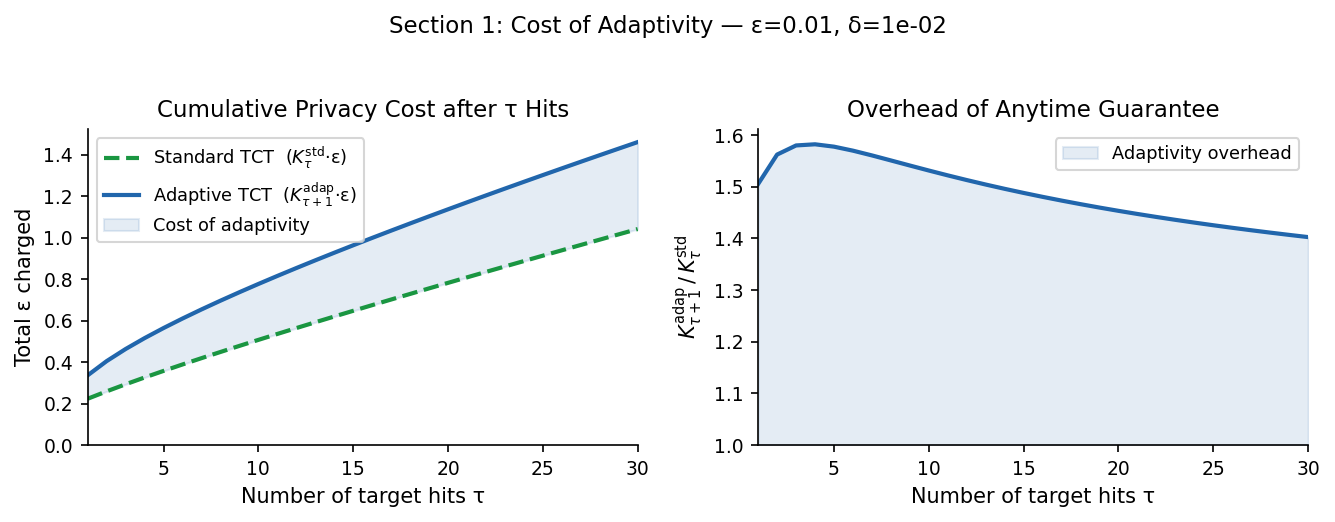

 tau       IDP     Std TCT    Adap TCT   Overhead
--------------------------------------------------
   1     0.010       0.224       0.336      1.505x
   5     0.050       0.358       0.565      1.578x
  10     0.100       0.508       0.777      1.531x
  20     0.200       0.783       1.138      1.453x
  30     0.300       1.042       1.462      1.403x


In [30]:
tau_range = list(range(1, 31))

cost_idp   = [t * EPSILON for t in tau_range]                      # τ·ε
cost_adap  = [AdaptiveTCTAccountant(EPSILON, DELTA).compositions(t + 1) * EPSILON
              for t in tau_range]                                   # K_{τ+1}·ε
cost_std   = [StandardTCTAccountant(EPSILON, DELTA, tau=t).K_tau * EPSILON
              for t in tau_range]                                   # K_τ^{std}·ε

overhead = [a / s for a, s in zip(cost_adap, cost_std)]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

# ── Left: cost curves ─────────────────────────────────────────────────────────
ax = axes[0]
ax.plot(tau_range, cost_std,  color=STCT_COLOR, lw=2,   linestyle='--',
        label='Standard TCT  ($K_\\tau^{\\mathrm{std}}$·ε)')
ax.plot(tau_range, cost_adap, color=TCT_COLOR,  lw=2,
        label='Adaptive TCT  ($K_{\\tau+1}^{\\mathrm{adap}}$·ε)')
ax.fill_between(tau_range, cost_std, cost_adap, alpha=0.12, color=TCT_COLOR,
                label='Cost of adaptivity')
ax.set_xlabel('Number of target hits τ')
ax.set_ylabel('Total ε charged')
ax.set_title('Cumulative Privacy Cost after τ Hits')
ax.set_xlim(1, 30)
ax.set_ylim(bottom=0)
ax.legend(loc='upper left')

# ── Right: overhead ratio ─────────────────────────────────────────────────────
ax = axes[1]
ax.plot(tau_range, overhead, color=TCT_COLOR, lw=2)
ax.fill_between(tau_range, 1.0, overhead, alpha=0.12, color=TCT_COLOR,
                label='Adaptivity overhead')
ax.set_xlabel('Number of target hits τ')
ax.set_ylabel('$K_{\\tau+1}^{\\mathrm{adap}}\\,/\\,K_\\tau^{\\mathrm{std}}$')
ax.set_title('Overhead of Anytime Guarantee')
ax.set_xlim(1, 30)
ax.set_ylim(bottom=1.0)
ax.legend(loc='upper right')

fig.suptitle(
    f'Section 1: Cost of Adaptivity — ε={EPSILON}, δ={DELTA:.0e}',
    fontsize=11,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/h1_cost_of_adaptivity.png', bbox_inches='tight', dpi=200)
plt.show()

print(f"{'tau':>4}  {'IDP':>8}  {'Std TCT':>10}  {'Adap TCT':>10}  {'Overhead':>9}")
print('-' * 50)
for i, t in enumerate([1, 5, 10, 20, 30]):
    j = t - 1
    print(f'{t:>4}  {cost_idp[j]:>8.3f}  {cost_std[j]:>10.3f}  '
          f'{cost_adap[j]:>10.3f}  {overhead[j]:>9.3f}x')

## Section 2: Full Participation, No Interleaving

Simplest setting: all active users participate every round; every round is a TCT query.

- **Standard IDP** charges all N users ε per round → exhausts at round EPS_BUDGET/ε = **100**.
- **Adaptive TCT** charges K₁·ε ≈ 0.224 at registration (for δ=1e-2), then only at target hits → exhausts far later.

This is the maximally favourable regime for TCT.

Section 2: running simulations (full participation, no interleaving)...
Done.
TCT half-life: 500   IDP half-life: 99   Advantage: +401 rounds  (405%)


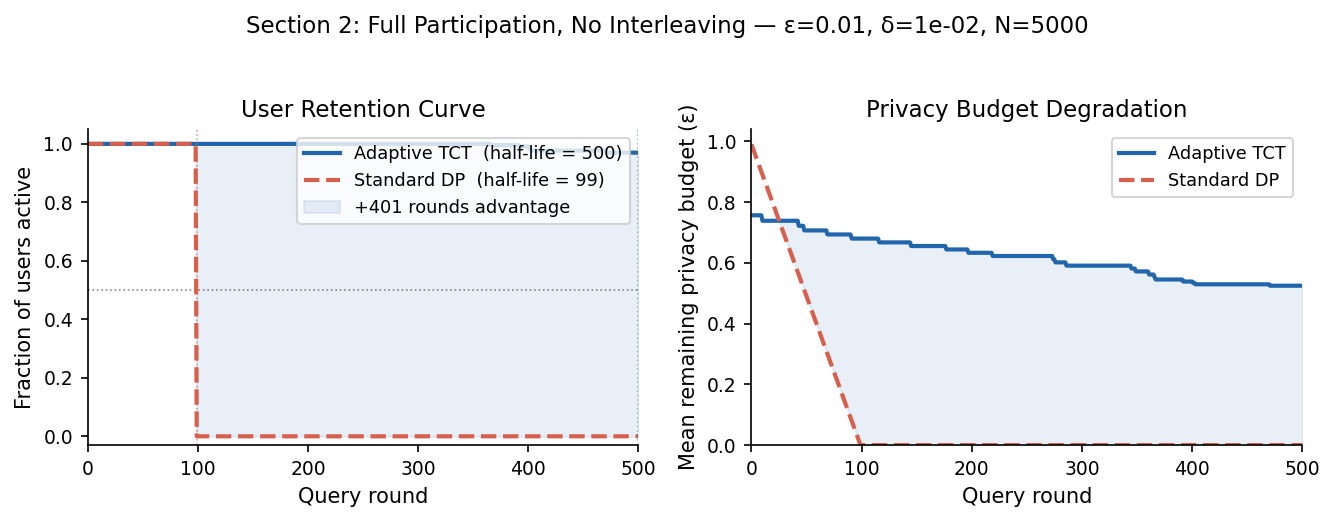

In [31]:
print('Section 2: running simulations (full participation, no interleaving)...')
tct2_frac, tct2_budget, tct2_hits = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, independent=True),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=0.0)
idp2_frac, idp2_budget, idp2_hits = run_simulation(
    lambda: StandardDPAccountant(EPSILON),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=0.0)
print('Done.')

hl_tct2 = half_life(tct2_frac)
hl_idp2 = half_life(idp2_frac)
print(f'TCT half-life: {hl_tct2}   IDP half-life: {hl_idp2}   '
      f'Advantage: +{hl_tct2 - hl_idp2} rounds  '
      f'({100*(hl_tct2-hl_idp2)/hl_idp2:.0f}%)')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
plot_h1_panel(axes, tct2_frac, tct2_budget, idp2_frac, idp2_budget,
              hl_tct2, hl_idp2,
              'User Retention Curve', 'Privacy Budget Degradation')
fig.suptitle(
    f'Section 2: Full Participation, No Interleaving — '
    f'ε={EPSILON}, δ={DELTA:.0e}, N={N_USERS}',
    fontsize=11,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/h1_full_no_interleave.png', bbox_inches='tight', dpi=200)
plt.show()

### Robustness: Section 2

Repeat Section 2 (full participation, no interleaving) across three parameter settings.

| Setting | δ | Population | E[rate] |
|---|---|---|---|
| A | 1e-2 | Moderate (α=0.5, β=2.0) | 0.200 |
| B | 1e-3 | Moderate (α=0.5, β=2.0) | 0.200 |
| C | 1e-2 | Sparse (α=0.3, β=3.0)   | 0.091 |

Robustness Section 2: full participation, no interleaving...
A  (δ=1e-2, moderate)           K₁·ε=0.244  TCT_hl=500  IDP_hl=99  adv=+401
B  (δ=1e-3, moderate)           K₁·ε=0.337  TCT_hl=500  IDP_hl=99  adv=+401
C  (δ=1e-2, sparse)             K₁·ε=0.244  TCT_hl=500  IDP_hl=99  adv=+401


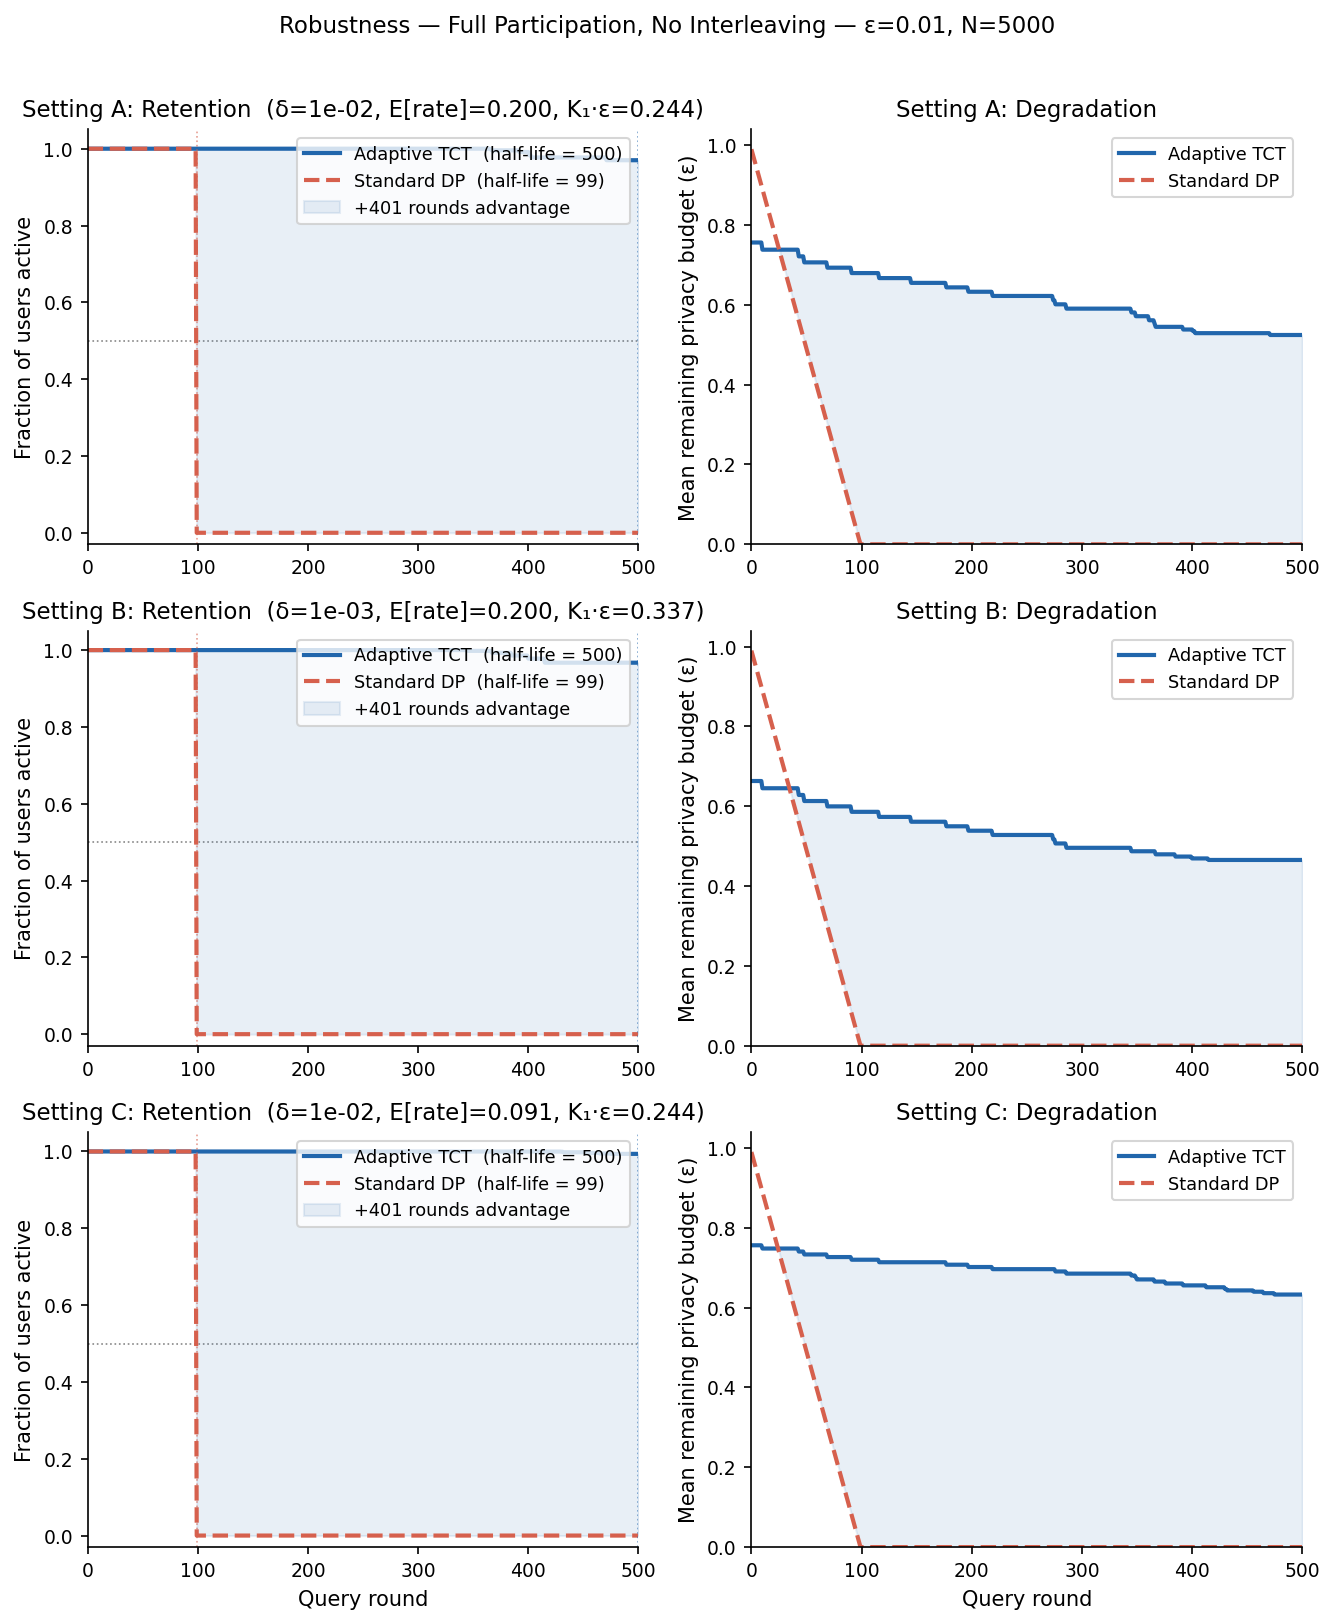

In [32]:
print('Robustness Section 2: full participation, no interleaving...')
robust2 = run_robust_settings(ROBUST_SETTINGS, p_participate=1.0, interleave_ratio=0.0)
plot_robust_settings(
    robust2,
    f'Full Participation, No Interleaving — ε={EPSILON}, N={N_USERS}',
    '../figures/h1_s2_robustness.png',
)

## Section 3: Full Participation, With Interleaving

30% of rounds are non-TCT (standard DP composition). Both accountants pay ε directly on non-TCT rounds.

- **Standard IDP** is unchanged: it charges ε every round regardless of TCT/non-TCT status → still exhausts at round **100**.
- **Adaptive TCT** pays ε on non-TCT rounds plus registration plus hit charges → exhausts later than IDP but earlier than the no-interleaving case.

Interleaving reduces but does not eliminate TCT's advantage.

Section 3: running simulations (full participation, interleave=0.5)...
Done.
TCT half-life: 130   IDP half-life: 99   Advantage: +31 rounds
Note: IDP half-life should match Section 2 (99) — OK


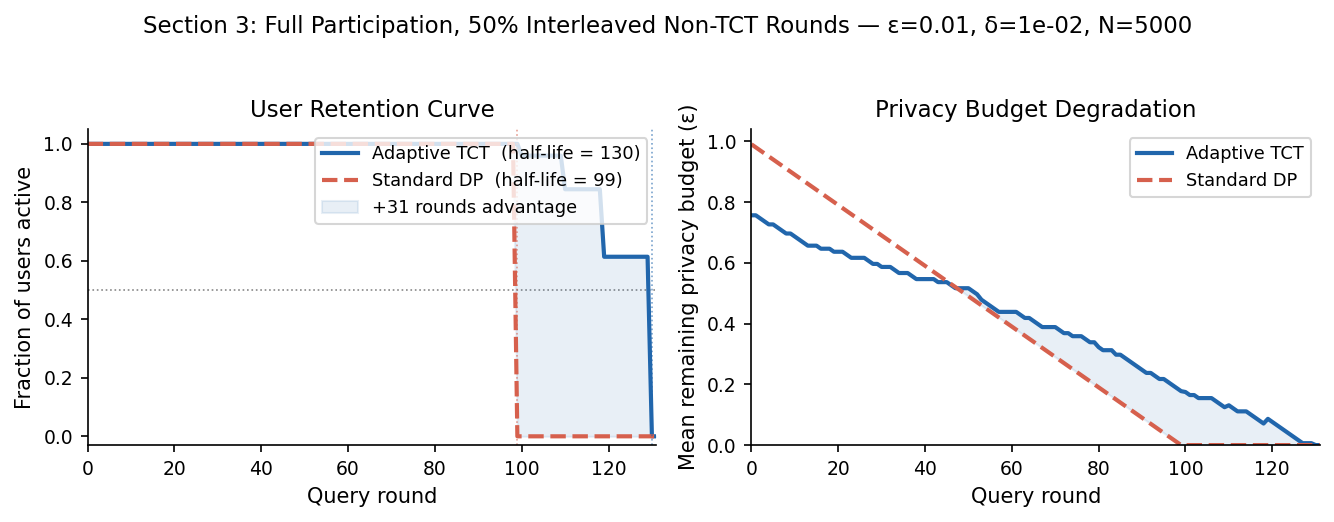

In [33]:
print('Section 3: running simulations (full participation, interleave=0.5)...')
tct3_frac, tct3_budget, tct3_hits = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, independent=True),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=INTERLEAVE)
idp3_frac, idp3_budget, idp3_hits = run_simulation(
    lambda: StandardDPAccountant(EPSILON),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=INTERLEAVE)
print('Done.')

hl_tct3 = half_life(tct3_frac)
hl_idp3 = half_life(idp3_frac)
print(f'TCT half-life: {hl_tct3}   IDP half-life: {hl_idp3}   '
      f'Advantage: +{hl_tct3 - hl_idp3} rounds')
print(f'Note: IDP half-life should match Section 2 ({hl_idp2}) — '
      f'{"OK" if hl_idp3 == hl_idp2 else "differs (seed variation)"}')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
plot_h1_panel(axes, tct3_frac, tct3_budget, idp3_frac, idp3_budget,
              hl_tct3, hl_idp3,
              'User Retention Curve', 'Privacy Budget Degradation')
fig.suptitle(
    f'Section 3: Full Participation, 50% Interleaved Non-TCT Rounds — '
    f'ε={EPSILON}, δ={DELTA:.0e}, N={N_USERS}',
    fontsize=11,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/h1_full_interleaved.png', bbox_inches='tight', dpi=200)
plt.show()

### Robustness: Section 3

Repeat Section 3 (full participation, 30% interleaving) across three parameter settings.

| Setting | δ | Population | E[rate] |
|---|---|---|---|
| A | 1e-2 | Moderate (α=0.5, β=2.0) | 0.200 |
| B | 1e-3 | Moderate (α=0.5, β=2.0) | 0.200 |
| C | 1e-2 | Sparse (α=0.3, β=3.0)   | 0.091 |

Robustness Section 3: full participation, 30% interleaving...
A  (δ=1e-2, moderate)           K₁·ε=0.244  TCT_hl=130  IDP_hl=99  adv=+31
B  (δ=1e-3, moderate)           K₁·ε=0.337  TCT_hl=141  IDP_hl=99  adv=+42
C  (δ=1e-2, sparse)             K₁·ε=0.244  TCT_hl=150  IDP_hl=99  adv=+51


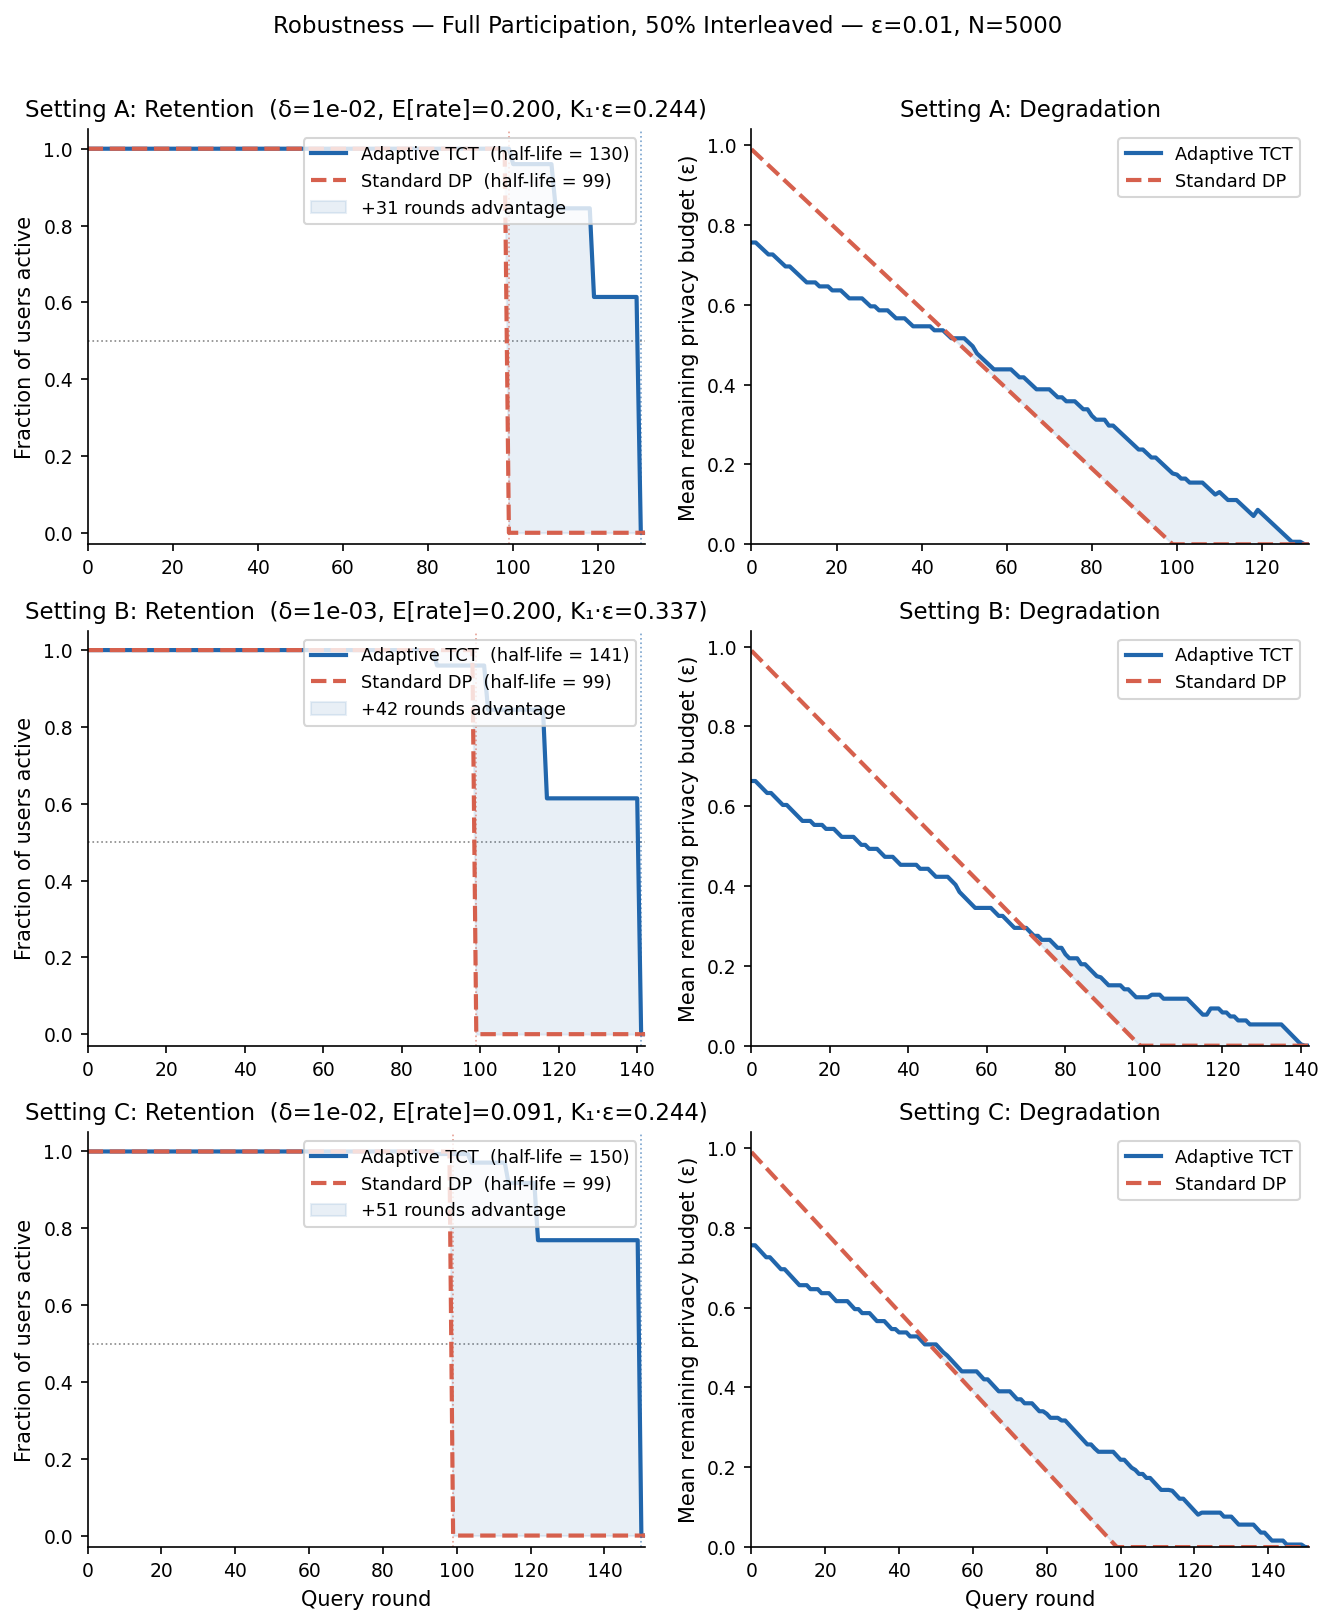

In [34]:
print('Robustness Section 3: full participation, 30% interleaving...')
robust3 = run_robust_settings(ROBUST_SETTINGS, p_participate=1.0, interleave_ratio=INTERLEAVE)
plot_robust_settings(
    robust3,
    f'Full Participation, 50% Interleaved — ε={EPSILON}, N={N_USERS}',
    '../figures/h1_s3_robustness.png',
)

## Section 4: Partial Participation (30%), With Interleaving

Each round, only 30% of active users are sampled (partial participation). 30% of rounds are non-TCT. The threshold is recalibrated to the partial-participation model.

- **Standard IDP** exhausts at EPS_BUDGET / (p·ε) = **333 rounds**.
- **Adaptive TCT** registration remains K₁·ε; non-TCT charges are diluted by p and interleave rate → exhausts later.

This is the most realistic deployment scenario: individual privacy with query-level sub-sampling.

Section 4: running simulations (partial participation, interleave=0.5)...
Done.
TCT half-life: 310   IDP half-life: 198   Advantage: +112 rounds  (57%)


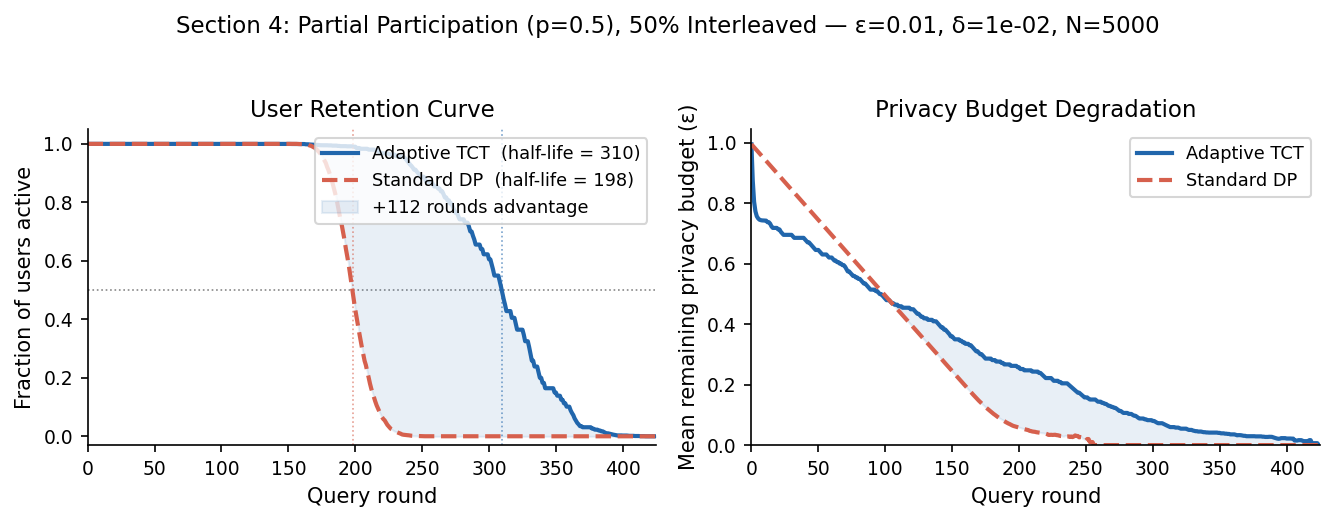

In [35]:
print('Section 4: running simulations (partial participation, interleave=0.5)...')
tct4_frac, tct4_budget, tct4_hits = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, independent=True),
    pop_cfg, T_partial, p_participate=P_PART, interleave_ratio=INTERLEAVE)
idp4_frac, idp4_budget, idp4_hits = run_simulation(
    lambda: StandardDPAccountant(EPSILON),
    pop_cfg, T_partial, p_participate=P_PART, interleave_ratio=INTERLEAVE)
print('Done.')

hl_tct4 = half_life(tct4_frac)
hl_idp4 = half_life(idp4_frac)
print(f'TCT half-life: {hl_tct4}   IDP half-life: {hl_idp4}   '
      f'Advantage: +{hl_tct4 - hl_idp4} rounds  '
      f'({100*(hl_tct4-hl_idp4)/max(hl_idp4,1):.0f}%)')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
plot_h1_panel(axes, tct4_frac, tct4_budget, idp4_frac, idp4_budget,
              hl_tct4, hl_idp4,
              'User Retention Curve', 'Privacy Budget Degradation',
              label_suffix='')
fig.suptitle(
    f'Section 4: Partial Participation (p={P_PART}), 50% Interleaved — '
    f'ε={EPSILON}, δ={DELTA:.0e}, N={N_USERS}',
    fontsize=11,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/h1_partial_interleaved.png', bbox_inches='tight', dpi=200)
plt.show()

### Robustness: Section 4

Repeat Section 4 (partial participation + interleaving) across three parameter settings to confirm
the advantage is not regime-specific.

| Setting | δ | Population | E[rate] | K₁·ε |
|---|---|---|---|---|
| A | 1e-2 | Moderate (α=0.5, β=2.0) | 0.200 | ≈ 0.224 |
| B | 1e-3 | Moderate (α=0.5, β=2.0) | 0.200 | ≈ 0.317 |
| C | 1e-2 | Sparse (α=0.3, β=3.0)   | 0.091 | ≈ 0.224 |

In [36]:
print('Robustness Section 4: partial participation, 50% interleaving...')
robust4 = run_robust_settings(ROBUST_SETTINGS, p_participate=P_PART, interleave_ratio=INTERLEAVE)

Robustness Section 4: partial participation, 50% interleaving...
A  (δ=1e-2, moderate)           K₁·ε=0.244  TCT_hl=310  IDP_hl=198  adv=+112
B  (δ=1e-3, moderate)           K₁·ε=0.337  TCT_hl=254  IDP_hl=198  adv=+56
C  (δ=1e-2, sparse)             K₁·ε=0.244  TCT_hl=292  IDP_hl=198  adv=+94


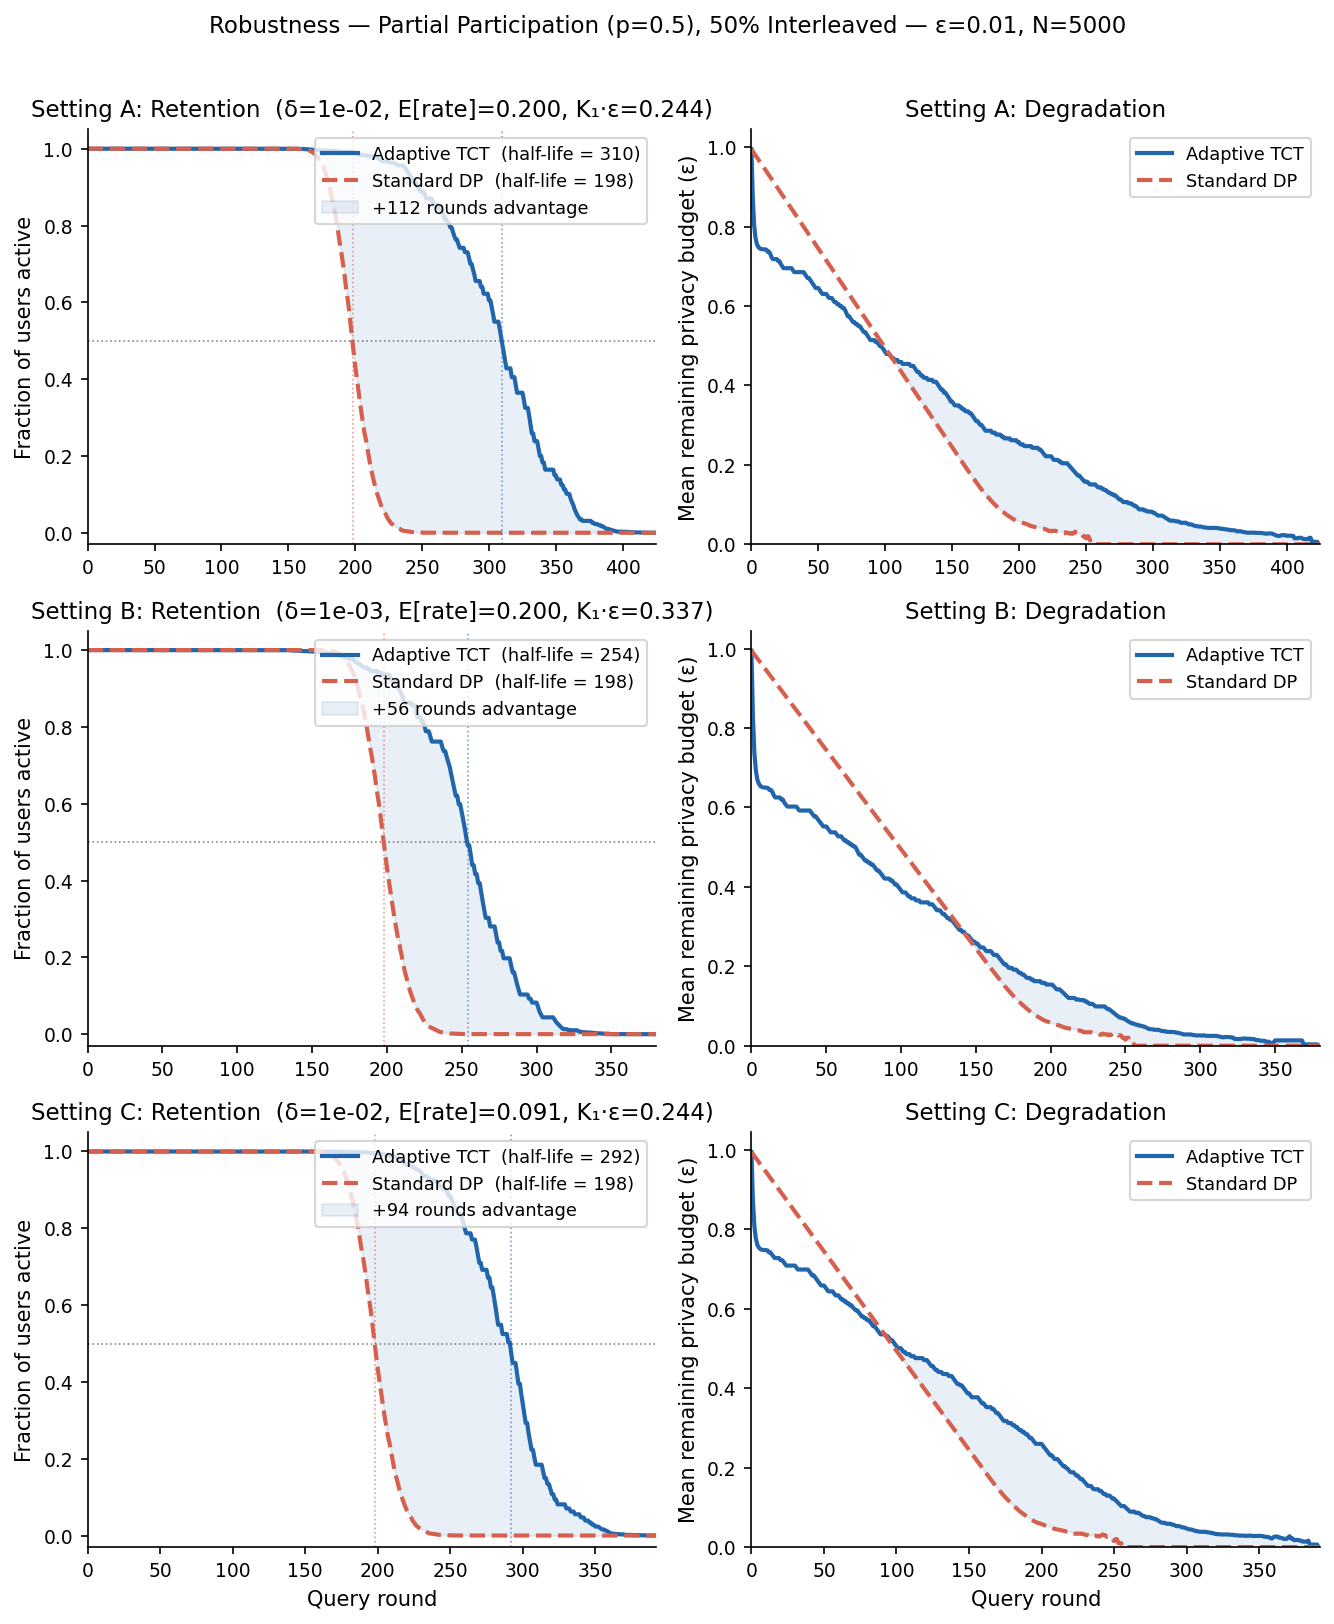

In [37]:
plot_robust_settings(
    robust4,
    f'Partial Participation (p={P_PART}), 50% Interleaved — ε={EPSILON}, N={N_USERS}',
    '../figures/h1_s4_robustness.png',
)

## Section 6: Summary

                       Scenario   p  interleave  TCT_hl  IDP_hl  Adv Adv (%)
        S2: Full, no interleave 1.0         0.0     500      99  401    405%
       S3: Full, interleave 30% 1.0         0.3     130      99   31     31%
S4: Partial 30%, interleave 30% 0.5         0.5     310     198  112     57%
                       S2-Rob-A 1.0         0.0     500      99  401    405%
                       S2-Rob-B 1.0         0.0     500      99  401    405%
                       S2-Rob-C 1.0         0.0     500      99  401    405%
                       S3-Rob-A 1.0         0.5     130      99   31     31%
                       S3-Rob-B 1.0         0.5     141      99   42     42%
                       S3-Rob-C 1.0         0.5     150      99   51     52%
                       S4-Rob-A 0.5         0.5     310     198  112     57%
                       S4-Rob-B 0.5         0.5     254     198   56     28%
                       S4-Rob-C 0.5         0.5     292     198   94     47%

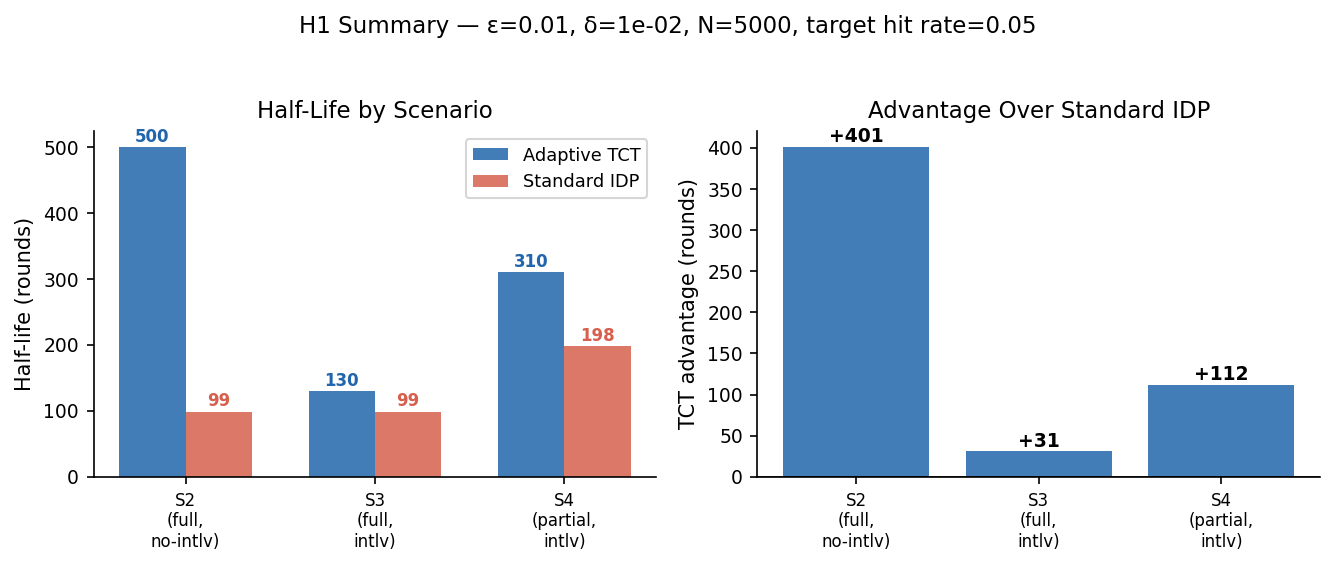

In [38]:
# ── Progression table ─────────────────────────────────────────────────────────
rows = [
    {'Scenario': 'S2: Full, no interleave',         'p': 1.0,    'interleave': 0.0,
     'TCT_hl': hl_tct2, 'IDP_hl': hl_idp2, 'Adv': hl_tct2-hl_idp2},
    {'Scenario': 'S3: Full, interleave 30%',         'p': 1.0,    'interleave': 0.3,
     'TCT_hl': hl_tct3, 'IDP_hl': hl_idp3, 'Adv': hl_tct3-hl_idp3},
    {'Scenario': 'S4: Partial 30%, interleave 30%',  'p': P_PART, 'interleave': INTERLEAVE,
     'TCT_hl': hl_tct4, 'IDP_hl': hl_idp4, 'Adv': hl_tct4-hl_idp4},
]
robust_runs = [
    ('S2-Rob', robust2, 1.0,    0.0),
    ('S3-Rob', robust3, 1.0,    INTERLEAVE),
    ('S4-Rob', robust4, P_PART, INTERLEAVE),
]
for tag, robust_list, p_val, intlv_val in robust_runs:
    for res in robust_list:
        rows.append({'Scenario': f"{tag}-{res['label'][:1]}",
                     'p': p_val, 'interleave': intlv_val,
                     'TCT_hl': res['hl_tct'], 'IDP_hl': res['hl_idp'],
                     'Adv': res['advantage']})

df = pd.DataFrame(rows)
df['Adv (%)'] = (100 * df['Adv'] / df['IDP_hl'].clip(lower=1)).round(0).astype(int).astype(str) + '%'
print(df[['Scenario','p','interleave','TCT_hl','IDP_hl','Adv','Adv (%)']].to_string(index=False))

# ── Summary bar chart (main scenarios only) ────────────────────────────────────
main_labels  = ['S2\n(full,\nno-intlv)', 'S3\n(full,\nintlv)', 'S4\n(partial,\nintlv)']
main_tct_hls = [hl_tct2, hl_tct3, hl_tct4]
main_idp_hls = [hl_idp2, hl_idp3, hl_idp4]
main_adv     = [hl_tct2-hl_idp2, hl_tct3-hl_idp3, hl_tct4-hl_idp4]

x = np.arange(3)
w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))

ax = axes[0]
ax.bar(x - w/2, main_tct_hls, w, color=TCT_COLOR, alpha=0.85, label='Adaptive TCT')
ax.bar(x + w/2, main_idp_hls, w, color=IDP_COLOR, alpha=0.85, label='Standard IDP')
for i, (t, d) in enumerate(zip(main_tct_hls, main_idp_hls)):
    ax.text(i - w/2, t + 2, str(t), ha='center', va='bottom', fontsize=8,
            color=TCT_COLOR, fontweight='bold')
    ax.text(i + w/2, d + 2, str(d), ha='center', va='bottom', fontsize=8,
            color=IDP_COLOR, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(main_labels, fontsize=8)
ax.set_ylabel('Half-life (rounds)')
ax.set_title('Half-Life by Scenario')
ax.legend()

ax = axes[1]
bars = ax.bar(x, main_adv, color=TCT_COLOR, alpha=0.85)
for bar, adv in zip(bars, main_adv):
    ax.text(bar.get_x() + bar.get_width()/2, adv + 1, f'+{adv}',
            ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(main_labels, fontsize=8)
ax.set_ylabel('TCT advantage (rounds)')
ax.set_title('Advantage Over Standard IDP')
ax.axhline(0, color='black', lw=0.8)

fig.suptitle(
    f'H1 Summary — ε={EPSILON}, δ={DELTA:.0e}, N={N_USERS}, '
    f'target hit rate={TARGET_HIT_RATE}',
    fontsize=11,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/h1_summary.png', bbox_inches='tight', dpi=200)
plt.show()